=== BREUSCH-PAGAN HETEROSKEDASTICITY TEST ===
LM Statistic: 12.7275 | LM p-value: 0.623338 | F-stat: 0.8462

=== VIF ANALYSIS ===


,Variable,VIF
0,Intercept,53.56
1,"C(position, Treatment(reference=""Defender""))[T...",11.87
2,"C(position, Treatment(reference=""Defender""))[T...",16.44
3,C(club_tier)[T.Tier 2],1.56
4,C(club_tier)[T.Tier 3],1.54
5,C(league)[T.EPL],1.51
6,C(league)[T.La Liga],1.53
7,C(league)[T.Ligue 1],1.53
8,C(league)[T.Serie A],1.48
9,age_centered,1.01


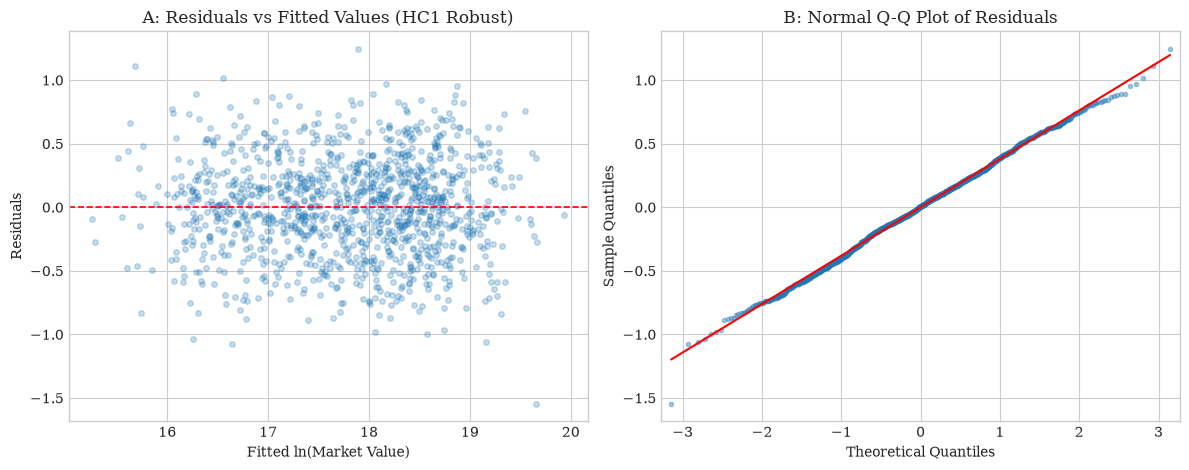

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv("cleaned_players_data.csv")

formula = 'log_market_value ~ C(position, Treatment(reference="Defender")) + age_centered + age_centered_sq + minutes_played + contract_years + C(club_tier) + C(league) + xg_filled + prog_passes_filled + tackles_filled'
ols_fit = smf.ols(formula, data=df).fit(cov_type="HC1")

# 1. Breusch-Pagan Test
bp = het_breuschpagan(ols_fit.resid, ols_fit.model.exog)
print("=== BREUSCH-PAGAN HETEROSKEDASTICITY TEST ===")
print(f"LM Statistic: {bp[0]:.4f} | LM p-value: {bp[1]:.6f} | F-stat: {bp[2]:.4f}")

# 2. VIF Check
exog = ols_fit.model.exog
vif_df = pd.DataFrame({
    "Variable": ols_fit.model.exog_names,
    "VIF": [round(variance_inflation_factor(exog, i), 2) for i in range(exog.shape[1])]
})
print("\n=== VIF ANALYSIS ===")
display(vif_df)

# 3. Figure 4: Residual Diagnostics
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.family": "serif", "font.size": 10})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(ols_fit.fittedvalues, ols_fit.resid, alpha=0.25, s=16, color="#1f77b4")
axes[0].axhline(0, color="red", linestyle="--", linewidth=1.2)
axes[0].set_title("A: Residuals vs Fitted Values (HC1 Robust)")
axes[0].set_xlabel("Fitted ln(Market Value)")
axes[0].set_ylabel("Residuals")

sm.qqplot(ols_fit.resid, line="s", ax=axes[1], markersize=3, alpha=0.4)
axes[1].set_title("B: Normal Q-Q Plot of Residuals")
fig.tight_layout()
fig.savefig("fig4_residual_diagnostics.png", dpi=300, bbox_inches="tight")
fig.savefig("fig4_residual_diagnostics.pdf", bbox_inches="tight")
plt.show()

In [4]:

import time
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

# Тек нақты белгілерді алу (player_id және target алынып тасталады)
num_cols = ["age", "age_sq", "minutes_played", "contract_years", "tackles_filled", "prog_passes_filled", "xg_filled"]
cat_cols = ["position", "league", "club_tier"]
feature_cols = num_cols + cat_cols

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

models = {
    "OLS Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(n_estimators=200, learning_rate=0.05, random_state=42, verbose=-1),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42, verbosity=0),
}

X = df[feature_cols]
y_log = df["log_market_value"].values
y_eur_m = df["market_value"].values / 1e6
kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = []
for name, model in models.items():
    maes, rmses, mapes, adj_r2s, latencies = [], [], [], [], []
    for tr, va in kf.split(X):
        pipe = Pipeline([("prep", preprocessor), ("model", model)])
        pipe.fit(X.iloc[tr], y_log[tr])

        t0 = time.perf_counter()
        pred_log = pipe.predict(X.iloc[va])
        latencies.append((time.perf_counter() - t0) * 1000)

        pred_m = np.exp(pred_log)
        true_m = y_eur_m[va]

        maes.append(mean_absolute_error(true_m, pred_m))
        rmses.append(np.sqrt(mean_squared_error(true_m, pred_m)))
        mapes.append(np.mean(np.abs((true_m - pred_m) / true_m)) * 100)

        r2 = r2_score(y_log[va], pred_log)
        n_v, p = len(va), 15
        adj_r2s.append(1 - (1 - r2) * (n_v - 1) / (n_v - p - 1))

    results.append({
        "Model": name,
        "MAE (€M)": f"{np.mean(maes):.2f} ± {np.std(maes):.2f}",
        "RMSE (€M)": f"{np.mean(rmses):.2f} ± {np.std(rmses):.2f}",
        "MAPE (%)": f"{np.mean(mapes):.1f}%",
        "Adjusted R2": f"{np.mean(adj_r2s):.3f}",
        "Latency (ms)": f"{np.median(latencies):.1f}",
    })

bench_df = pd.DataFrame(results)
print("=== 5-FOLD CV MODEL BENCHMARKS ===")
display(bench_df)
bench_df.to_csv("model_benchmarks.csv", index=False)

=== 5-FOLD CV MODEL BENCHMARKS ===


,Model,MAE (€M),RMSE (€M),MAPE (%),Adjusted R2,Latency (ms)
0,OLS Regression,74258064.99 ± 2070918.71,95687152.56 ± 4068389.82,107694328.5%,0.828,28.6
1,Ridge Regression,74350623.25 ± 2177713.64,97064585.37 ± 4804057.71,107862058.5%,0.825,22.3
2,Random Forest,72693588.81 ± 2735899.52,92187982.93 ± 4084179.29,109883537.7%,0.772,134.2
3,LightGBM,73750404.15 ± 2101982.05,94739402.40 ± 3879305.11,108716323.6%,0.793,37.3
4,XGBoost,73779279.24 ± 1950269.59,93913543.78 ± 3177316.96,109894157.6%,0.793,39.8
